# Modelamiento y Evaluación de Resultados

**Caso de Estudio:** Spotify Tracks Dataset
**Asignatura:** MLY1101, Machine Learning
**Evaluación Parcial N°2**
**Por:** Felipe Ahumada Silva y Francisca Carrasco Lozano

Este notebook cubre las fases 4 y 5 de CRISP-DM (modelado y evaluación), construyendo sobre las
fases 1-3 ya documentadas en [`analisis_exploratorio.ipynb`](analisis_exploratorio.ipynb) y
[`preprocesamiento.ipynb`](preprocesamiento.ipynb). Es autocontenido (misma convención del
proyecto): reconstruye el dataset preparado desde el CSV crudo en las primeras secciones, sin
repetir la justificación de cada decisión de limpieza/preparación, ya documentada en los
notebooks anteriores, y luego entrena y evalúa:

- **Dos modelos supervisados de regresión** para predecir `popularity`: Regresión Lineal y
  Random Forest, comparados contra una línea base ingenua.
- **Dos modelos supervisados de clasificación**, como complemento: Regresión Logística y
  Random Forest Classifier, prediciendo si una canción tendrá popularidad alta o baja respecto
  a la mediana del catálogo, la misma señal que la regresión, vista como una decisión binaria
  en vez de un valor exacto.
- **Una técnica no supervisada (KMeans)** para segmentar canciones por su perfil de sonido,
  independiente de género y popularidad.

# Importación de librerías

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Memory

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score,
    mean_absolute_error, r2_score, roc_auc_score, silhouette_score
)
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

plt.style.use('bmh')

# En Apple Silicon, la librería BLAS del sistema (Accelerate) emite RuntimeWarning de
# "overflow"/"invalid value" espurios durante ciertas operaciones matriciales (regresión
# lineal, KMeans) que no corresponden a un problema real de los datos: se verificó que
# X_train_prep/X_test_prep no tienen NaN ni Inf, y las métricas resultantes son consistentes
# y reproducibles. Se silencian para no ensuciar la salida del notebook.
warnings.filterwarnings('ignore', category=RuntimeWarning)

# Reconstrucción del dataset preparado

Se reconstruye aquí el mismo dataset y pipeline de `preprocesamiento.ipynb` (misma consolidación
por `track_id` y por audio, mismo tratamiento de inválidos, mismas dos variables derivadas,
mismo pipeline de transformación). El detalle y la justificación de cada paso está documentado
celda a celda en ese notebook; aquí se reproduce sin repetir la justificación, solo para llegar
al mismo punto de partida (`X_train_prep`, `X_test_prep`, `y_train`, `y_test`).

In [2]:
df = pd.read_csv('../data/Spotify_Tracks_Dataset.csv', index_col=0)

# Consolidación: una fila por track_id único (ver justificación en el EDA)
agregaciones = {col: 'first' for col in df.columns if col not in ['track_id', 'track_genre', 'popularity']}
agregaciones['track_genre'] = lambda generos: ';'.join(sorted(set(generos)))
agregaciones['popularity'] = 'mean'

df = df.groupby('track_id', as_index=False).agg(agregaciones)
df['popularity'] = df['popularity'].round().astype(int)

# Registro con duration_ms = 0 y metadatos nulos: se descarta por ser un error de carga (ver EDA)
df = df[df['duration_ms'] > 0].reset_index(drop=True)

print(f'Filas tras consolidar por track_id: {len(df)} | Columnas: {df.shape[1]}')

Filas tras consolidar por track_id: 89740 | Columnas: 20


In [3]:
# Segundo nivel de consolidación: audio idéntico bajo track_id distinto.
audio_cols = ['duration_ms', 'danceability', 'energy', 'key', 'loudness', 'mode',
              'speechiness', 'acousticness', 'instrumentalness', 'liveness',
              'valence', 'tempo', 'time_signature']

filas_antes_audio = len(df)

agregaciones_audio = {
    col: 'first' for col in df.columns if col not in audio_cols + ['track_genre', 'popularity']
}
# ';'.join(sorted(set(generos))) por sí solo no alcanza acá: a esta altura cada 'generos'
# ya puede ser un string multi-género (ej. 'disney;show-tunes'), y set() deduplicaría por
# string completo, no por género individual, dejando géneros repetidos (ej.
# 'disney;disney;show-tunes'). Se aplanan todos los tokens antes de deduplicar.
agregaciones_audio['track_genre'] = lambda generos: ';'.join(sorted(set(';'.join(generos).split(';'))))
agregaciones_audio['popularity'] = 'mean'

df = df.groupby(audio_cols, as_index=False).agg(agregaciones_audio)
df['popularity'] = df['popularity'].round().astype(int)

print(f'Filas antes de consolidar por audio: {filas_antes_audio}')
print(f'Filas después (dataset final): {len(df)} (-{filas_antes_audio - len(df)})')

Filas antes de consolidar por audio: 89740
Filas después (dataset final): 83478 (-6262)


In [4]:
# Valores inválidos detectados en el EDA: se marcan como NaN para
# que el SimpleImputer del pipeline los complete, en vez de descartar la fila completa.
mask_time_signature_invalido = df['time_signature'] == 0
mask_tempo_invalido = df['tempo'] == 0

df.loc[mask_time_signature_invalido, 'time_signature'] = np.nan
df.loc[mask_tempo_invalido, 'tempo'] = np.nan

print(f"time_signature = 0 marcados como NaN: {mask_time_signature_invalido.sum()} filas")
print(f"tempo = 0 marcados como NaN: {mask_tempo_invalido.sum()} filas")

# Ingeniería de características
df['distancia_duracion_optima'] = (df['duration_ms'] / 60000 - 3.75).abs()
df['es_calmado_positivo'] = ((df['valence'] >= 0.5) & (df['energy'] < 0.5)).astype(int)

time_signature = 0 marcados como NaN: 129 filas
tempo = 0 marcados como NaN: 124 filas


In [5]:
target = 'popularity'

features_num = [
    'duration_ms', 'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo',
    'distancia_duracion_optima'
]
features_cat = ['key', 'mode', 'time_signature', 'explicit', 'es_calmado_positivo']
feature_genero = ['track_genre']

X = df[features_num + features_cat + feature_genero]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f'Entrenamiento: {X_train.shape} | Prueba: {X_test.shape}')

Entrenamiento: (66782, 17) | Prueba: (16696, 17)


## Transformadores y pipeline de preparación

Idénticos a los definidos y justificados en `preprocesamiento.ipynb`: `Winsorizer` (recorte de
atípicos calibrado por columna), `CorrelationFilter` (elimina variables con |r| > 0,9),
`DataFrameConverter` (conserva nombres de columnas tras el `ColumnTransformer`) y
`GenreMeanEncoder` (codifica `track_genre` como el promedio de popularidad histórica, ajustado
solo con el conjunto de entrenamiento para no filtrar información hacia el conjunto de prueba).

In [6]:
class Winsorizer(BaseEstimator, TransformerMixin):
    """
    Tratamiento de atípicos vía recorte por percentiles.

    limits acepta una tupla (mismo recorte para todas las columnas, comportamiento
    original) o un diccionario {columna: (inferior, superior)} para darle a cada
    columna su propio recorte. Una columna con (0.0, 0.0) no se recorta (quantile(0) y
    quantile(1) son el mínimo y el máximo de la columna, np.clip no cambia nada).
    """
    def __init__(self, limits=(0.05, 0.05)):
        self.limits = limits

    def _limites_columna(self, col):
        if isinstance(self.limits, dict):
            return self.limits.get(col, (0.0, 0.0))
        return self.limits

    def fit(self, X, y=None):
        if isinstance(X, pd.DataFrame):
            self.columns_ = X.columns
        else:
            self.columns_ = np.arange(X.shape[1])
        return self

    def transform(self, X):
        X = pd.DataFrame(X, columns=self.columns_).astype('float64')
        for col in self.columns_:
            inferior, superior = self._limites_columna(col)
            if inferior == 0 and superior == 0:
                continue
            lower = X[col].quantile(inferior)
            upper = X[col].quantile(1 - superior)
            X[col] = np.clip(X[col], lower, upper)
        return X

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            return np.array(self.columns_)
        return np.array(input_features)

In [7]:
class CorrelationFilter(BaseEstimator, TransformerMixin):
    """
    Elimina variables con alta correlación (multicolinealidad).
    """
    def __init__(self, threshold=0.9):
        self.threshold = threshold
        self.columns_to_drop_ = None

    def fit(self, X, y=None):
        X_df = pd.DataFrame(X)
        corr_matrix = X_df.corr().abs()
        upper = corr_matrix.where(
            np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
        )
        self.columns_to_drop_ = [
            col for col in upper.columns if any(upper[col] > self.threshold)
        ]
        return self

    def transform(self, X):
        X_df = pd.DataFrame(X)
        return X_df.drop(columns=self.columns_to_drop_, errors='ignore').values

In [8]:
class DataFrameConverter(BaseEstimator, TransformerMixin):
    """
    Convierte el array de ColumnTransformer en DataFrame con nombres de columnas.
    """
    def __init__(self, preprocessor):
        self.preprocessor = preprocessor
        self.feature_names_ = None

    def fit(self, X, y=None):
        self.feature_names_ = self.preprocessor.get_feature_names_out()
        return self

    def transform(self, X):
        return pd.DataFrame(X, columns=self.feature_names_)

In [9]:
class GenreMeanEncoder(BaseEstimator, TransformerMixin):
    """
    Codifica track_genre (multietiqueta, géneros separados por ';') como el promedio de
    popularidad histórica de sus géneros. Para una canción con más de un género se promedian
    las medias de cada uno. Las medias se calculan exclusivamente sobre los datos vistos en
    fit (el conjunto de entrenamiento), para no filtrar información del target de prueba.
    """
    def __init__(self, column='track_genre'):
        self.column = column

    def fit(self, X, y):
        generos = X[self.column].str.split(';').explode()
        y_generos = y.loc[generos.index]
        self.medias_genero_ = y_generos.groupby(generos.values).mean()
        self.media_global_ = y.mean()
        return self

    def transform(self, X):
        def promedio_generos(generos_cancion):
            return np.mean([
                self.medias_genero_.get(genero, self.media_global_)
                for genero in generos_cancion
            ])
        columna = X[self.column].str.split(';').apply(promedio_generos)
        return columna.to_frame(name='genero_popularidad_media')

    def get_feature_names_out(self, input_features=None):
        return np.array(['genero_popularidad_media'])

In [10]:
limits_winsorizer = {
    'duration_ms':               (0.001, 0.045),
    'danceability':              (0.005, 0.000),
    'energy':                    (0.000, 0.000),
    'loudness':                  (0.055, 0.000),
    'speechiness':               (0.000, 0.100),   # tope: real es 11.9%
    'acousticness':              (0.000, 0.000),
    'instrumentalness':          (0.000, 0.100),   # tope: real es 21.5%
    'liveness':                  (0.000, 0.080),
    'valence':                   (0.000, 0.000),
    'tempo':                     (0.000, 0.004),
    'distancia_duracion_optima': (0.000, 0.050),
}

numeric_transformer = Pipeline(steps=[
    ('winsorizer', Winsorizer(limits_winsorizer)),
    ('imputer',    SimpleImputer(strategy='mean')),
    ('scaler',     StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot',  OneHotEncoder(drop='first', handle_unknown='ignore'))
])

genero_transformer = Pipeline(steps=[
    ('genero_encoder', GenreMeanEncoder()),
    ('scaler',         StandardScaler())
])

preprocesador = ColumnTransformer(
    transformers=[
        ('num',    numeric_transformer,    features_num),
        ('cat',    categorical_transformer, features_cat),
        ('genero', genero_transformer,     feature_genero)
    ],
    remainder='drop',
    force_int_remainder_cols=False
)

pipeline_preparacion = Pipeline(steps=[
    ('preprocesador', preprocesador),
    ('conversion',    DataFrameConverter(preprocesador)),
    ('colinealidad',  CorrelationFilter(threshold=0.9))
])

In [11]:
X_train_prep = pipeline_preparacion.fit_transform(X_train, y_train)
X_test_prep = pipeline_preparacion.transform(X_test)

columnas_descartadas = pipeline_preparacion.named_steps['colinealidad'].columns_to_drop_
columnas_finales = [
    col for col in pipeline_preparacion.named_steps['conversion'].feature_names_
    if col not in columnas_descartadas
]

X_train_prep = pd.DataFrame(X_train_prep, columns=columnas_finales)
X_test_prep = pd.DataFrame(X_test_prep, columns=columnas_finales)

print(f'Forma final -> Entrenamiento: {X_train_prep.shape} | Prueba: {X_test_prep.shape}')
print(f'Valores nulos en X_train_prep: {X_train_prep.isna().sum().sum()}')
print(f'Valores nulos en X_test_prep: {X_test_prep.isna().sum().sum()}')

Forma final -> Entrenamiento: (66782, 29) | Prueba: (16696, 29)
Valores nulos en X_train_prep: 0
Valores nulos en X_test_prep: 0


# Fase 4: Modelado

Se construyen y comparan dos modelos supervisados de regresión para predecir `popularity`
sobre el dataset preparado, y se aplica una técnica no supervisada (KMeans) para descubrir
segmentos de canciones por perfil de sonido. Ambas tareas se apoyan en el mismo pipeline de
preparación recién ajustado, sin fuga de información (fit solo sobre el conjunto de
entrenamiento).

## 1. Línea base ingenua

Punto de comparación mínimo: predecir siempre el promedio de `popularity` del conjunto de
entrenamiento, sin usar ninguna variable. Cualquier modelo entrenado debe superar claramente
esta línea base para justificar su uso.

In [12]:
resultados = []

def evaluar_modelo(nombre, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    resultados.append({'modelo': nombre, 'MAE': mae, 'R2': r2})
    print(f'{nombre:28s} MAE={mae:6.3f}  R2={r2:7.4f}')
    return mae, r2

pred_baseline = np.full(shape=len(y_test), fill_value=y_train.mean())
evaluar_modelo('Baseline (promedio)', y_test, pred_baseline)


Baseline (promedio)          MAE=16.126  R2=-0.0006


(16.126373745844223, -0.0006011592648258457)

## 2. Modelo supervisado 1: Regresión Lineal

**Por qué este modelo:** es el modelo más simple e interpretable posible, y sirve de referencia
directa de la correlación lineal medida en el EDA (ninguna variable de audio supera |r| = 0,13
con `popularity`). Si incluso combinando todas las variables, incluido el género, la señal más
fuerte, un modelo puramente lineal explica poco, confirma que la señal es débil o la relación
no es lineal; si explica una fracción sustancial, confirma que gran parte de la señal ya es
aditiva. No requiere ajuste de hiperparámetros: no se usa una variante regularizada
(Ridge/Lasso) porque `CorrelationFilter` ya resguarda la multicolinealidad más severa dentro
del pipeline.

In [13]:
regresion_lineal = LinearRegression()
regresion_lineal.fit(X_train_prep, y_train)
pred_lr = regresion_lineal.predict(X_test_prep)
evaluar_modelo('Regresión Lineal', y_test, pred_lr)

coeficientes = pd.Series(regresion_lineal.coef_, index=X_train_prep.columns)
print('\nCoeficientes de mayor magnitud (variables ya estandarizadas, comparables entre sí):')
print(coeficientes.reindex(coeficientes.abs().sort_values(ascending=False).index).head(10).round(3))

Regresión Lineal             MAE=10.752  R2= 0.3874

Coeficientes de mayor magnitud (variables ya estandarizadas, comparables entre sí):
genero__genero_popularidad_media    11.710
cat__explicit_1.0                    2.193
num__energy                         -1.276
num__loudness                        0.962
cat__key_8.0                         0.881
cat__time_signature_4.0              0.783
cat__key_3.0                         0.678
num__valence                        -0.550
cat__key_6.0                         0.517
num__acousticness                   -0.514
dtype: float64


## 3. Modelo supervisado 2: Random Forest Regressor

**Por qué este modelo:** a diferencia de la regresión lineal, un ensamble de árboles captura
interacciones y relaciones no lineales entre variables de audio y género sin necesidad de
especificarlas a mano. Es además robusto a los atípicos residuales que deja el Winsorizer y no
asume una forma funcional particular entre las variables y `popularity`.

**Configuración:** en vez de asumir una configuración de hiperparámetros, se contrasta la
versión por defecto de scikit-learn (`n_estimators=100`, sin límite de profundidad) contra una
ajustada mediante una búsqueda automatizada (`RandomizedSearchCV`), que prueba muchas
combinaciones y se queda con la de mejor desempeño en validación cruzada, en vez de elegir los
valores a mano.

In [14]:
rf_default = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_default.fit(X_train_prep, y_train)
pred_rf_default = rf_default.predict(X_test_prep)
evaluar_modelo('Random Forest (por defecto)', y_test, pred_rf_default)

Random Forest (por defecto)  MAE=10.047  R2= 0.4276


(10.046714781983708, 0.42764956846752)

**Ajuste automatizado de hiperparámetros (`RandomizedSearchCV`):** se explora un espacio de
5×6×5×4=600 combinaciones posibles de `n_estimators`, `max_depth`, `min_samples_leaf` y
`max_features`, muestreando 8 combinaciones al azar con validación cruzada de 3 folds (24
ajustes de Random Forest en total). Es el Random Forest que se usa en el resto del análisis.

Mejor combinación encontrada: {'n_estimators': 300, 'min_samples_leaf': 5, 'max_features': 0.7, 'max_depth': 22}
R² promedio en validación cruzada (train): 0.4348


Random Forest (RandomizedSearchCV) MAE= 9.984  R2= 0.4377


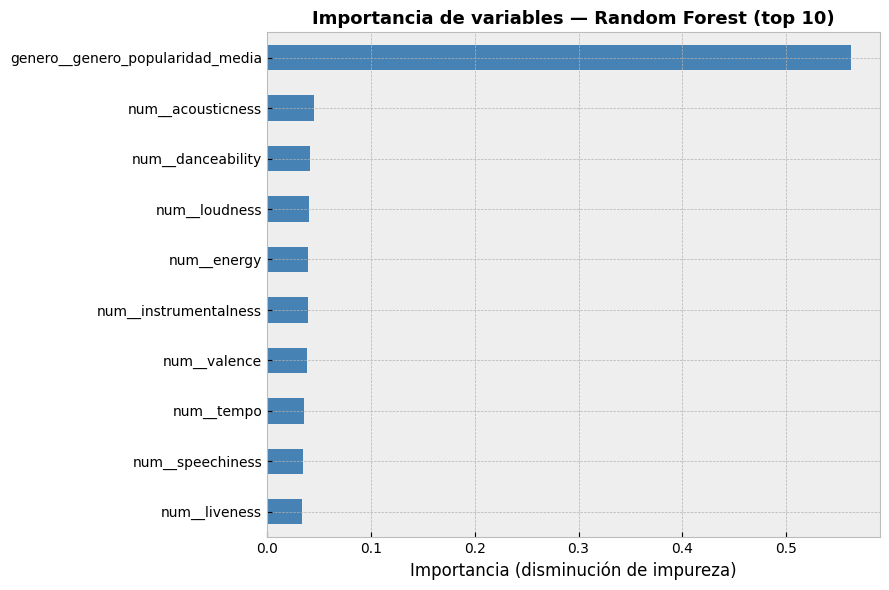

genero__genero_popularidad_media    0.562202
num__acousticness                   0.045375
num__danceability                   0.041800
num__loudness                       0.040908
num__energy                         0.039315
num__instrumentalness               0.039034
num__valence                        0.038850
num__tempo                          0.035512
num__speechiness                    0.034660
num__liveness                       0.034022
dtype: float64

In [15]:
param_dist = {
    'n_estimators': [100, 150, 200, 250, 300],
    'max_depth': [8, 12, 16, 18, 22, None],
    'min_samples_leaf': [1, 2, 3, 5, 8],
    'max_features': ['sqrt', 0.5, 0.7, 1.0],
}

# La búsqueda es determinística (mismos datos, mismo random_state en cada pieza), así que se
# cachea con joblib.Memory: la primera vez tarda lo normal (~5 min), pero si se reejecuta el
# notebook sin cambiar X_train_prep/y_train/param_dist, el resultado se sirve desde disco en
# segundos en vez de volver a entrenar 24 Random Forest. No cambia el resultado en absoluto,
# solo evita recalcular algo que ya se calculó.
memoria = Memory('../.cache_sklearn', verbose=0)

@memoria.cache
def ejecutar_busqueda_rf(X_train_prep, y_train, param_dist):
    busqueda = RandomizedSearchCV(
        RandomForestRegressor(random_state=42, n_jobs=1),
        param_distributions=param_dist,
        n_iter=8, cv=3, scoring='r2', random_state=42, n_jobs=-1
    )
    busqueda.fit(X_train_prep, y_train)
    return busqueda

busqueda_rf = ejecutar_busqueda_rf(X_train_prep, y_train, param_dist)

print(f'Mejor combinación encontrada: {busqueda_rf.best_params_}')
print(f'R² promedio en validación cruzada (train): {busqueda_rf.best_score_:.4f}')

random_forest = busqueda_rf.best_estimator_
pred_rf = random_forest.predict(X_test_prep)
evaluar_modelo('Random Forest (RandomizedSearchCV)', y_test, pred_rf)

importancias = pd.Series(random_forest.feature_importances_, index=X_train_prep.columns)
importancias = importancias.sort_values(ascending=False).head(10)

importancias.sort_values().plot(kind='barh', figsize=(9, 6), color='steelblue')
plt.title('Importancia de variables — Random Forest (top 10)', fontsize=13, fontweight='bold')
plt.xlabel('Importancia (disminución de impureza)')
plt.tight_layout()
plt.savefig('../images/importancia_variables_rf.png', dpi=150, bbox_inches='tight')
plt.show()

importancias

**Resultado:** la mejor combinación encontrada (`n_estimators=300, max_depth=22,
min_samples_leaf=5, max_features=0.7`) mejora sobre la configuración por defecto (R²=0,438 vs.
0,428), confirmando que vale la pena buscar hiperparámetros en vez de usar los valores de
fábrica. `genero_popularidad_media` domina la importancia de variables con ~56% del total,
consistente con el hallazgo del EDA: el género es, por lejos, la señal más fuerte del contenido
de la canción.

## 4. Comparación de modelos supervisados

                                        MAE      R2
modelo                                             
Baseline (promedio)                 16.1264 -0.0006
Regresión Lineal                    10.7517  0.3874
Random Forest (por defecto)         10.0467  0.4276
Random Forest (RandomizedSearchCV)   9.9845  0.4377


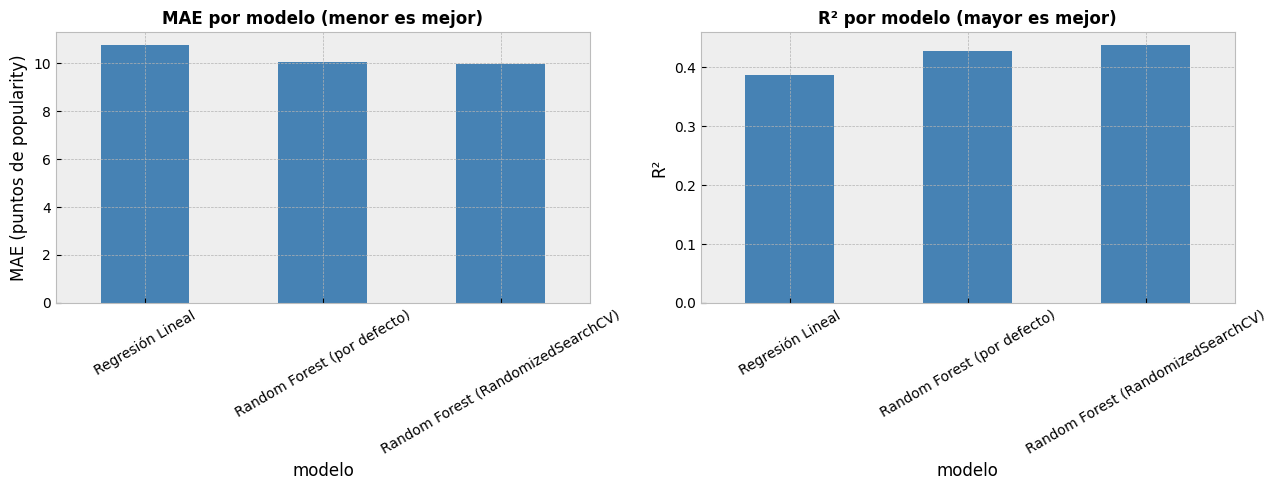

In [16]:
tabla_resultados = pd.DataFrame(resultados).set_index('modelo')
print(tabla_resultados.round(4))

# La línea base ingenua queda en la tabla (es el piso de comparación), pero se excluye de los
# gráficos: su escala (R²≈0, MAE≈16) aplana visualmente las diferencias entre los 3 modelos
# entrenados, que es lo que interesa comparar acá.
tabla_modelos = tabla_resultados.drop(index='Baseline (promedio)')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
tabla_modelos['MAE'].plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('MAE por modelo (menor es mejor)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('MAE (puntos de popularity)')
axes[0].tick_params(axis='x', rotation=30)

tabla_modelos['R2'].plot(kind='bar', ax=axes[1], color='steelblue')
axes[1].set_title('R² por modelo (mayor es mejor)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('R²')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('../images/comparacion_modelos.png', dpi=150, bbox_inches='tight')
plt.show()


## 5. Clasificación complementaria: ¿popularidad alta o baja?

Como complemento a la regresión, se entrena un segundo tipo de modelo supervisado sobre el
mismo problema de fondo: en vez de predecir el puntaje exacto de `popularity`, se clasifica
cada canción en **alta** o **baja** popularidad, usando la **mediana del conjunto de
entrenamiento** como corte (no la del conjunto completo, para no filtrar información del test).
Reutiliza exactamente el mismo pipeline de preparación y las mismas 29 columnas de
`X_train_prep`/`X_test_prep`, solo cambia qué se le pide al modelo que prediga.

**Por qué no es "repetir" la regresión:** son preguntas de negocio distintas sobre el mismo
fenómeno. La regresión responde *"¿cuál es el puntaje exacto esperado?"*; la clasificación
responde *"¿esta canción nueva suena como que va a tener mejor o peor desempeño que la mediana
del catálogo?"*, una pregunta más directamente accionable para decidir en qué invertir esfuerzo
de promoción, con sus propias métricas (accuracy, F1, AUC-ROC) en vez de MAE/R².

In [17]:
mediana_train = y_train.median()
print(f'Mediana de popularity en el conjunto de entrenamiento: {mediana_train}')

y_train_cls = (y_train > mediana_train).map({True: 'alta', False: 'baja'})
y_test_cls = (y_test > mediana_train).map({True: 'alta', False: 'baja'})

print('Distribución en entrenamiento:', y_train_cls.value_counts().to_dict())
print('Distribución en prueba:       ', y_test_cls.value_counts().to_dict())

Mediana de popularity en el conjunto de entrenamiento: 35.0
Distribución en entrenamiento: {'baja': 34257, 'alta': 32525}
Distribución en prueba:        {'baja': 8370, 'alta': 8326}


### Línea base, Regresión Logística y Random Forest

In [18]:
resultados_clasificacion = []

def evaluar_clasificador(nombre, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average='macro')
    resultados_clasificacion.append({'modelo': nombre, 'Accuracy': acc, 'F1_macro': f1})
    print(f'{nombre:28s} Accuracy={acc:6.4f}  F1_macro={f1:6.4f}')
    return acc, f1

clase_mayoritaria = y_train_cls.value_counts().idxmax()
pred_baseline_cls = pd.Series(clase_mayoritaria, index=y_test_cls.index)
evaluar_clasificador('Baseline (clase mayoritaria)', y_test_cls, pred_baseline_cls)

Baseline (clase mayoritaria) Accuracy=0.5013  F1_macro=0.3339


(0.5013176808816483, 0.3339184552780659)

**Regresión Logística**, el equivalente de clasificación de la Regresión Lineal: simple,
interpretable, y sirve de referencia directa antes de pasar a un modelo más complejo.

In [19]:
regresion_logistica = LogisticRegression(max_iter=1000)
regresion_logistica.fit(X_train_prep, y_train_cls)
pred_logit = regresion_logistica.predict(X_test_prep)
evaluar_clasificador('Regresión Logística', y_test_cls, pred_logit)

Regresión Logística          Accuracy=0.7768  F1_macro=0.7768


(0.7768327743172018, 0.7767663511222195)

**Random Forest Classifier**, ajustado con `RandomizedSearchCV` (mismo criterio y mismo
espacio de hiperparámetros que el Random Forest de regresión de la sección 3, para mantener
consistencia metodológica entre ambos modelos). El resultado también se cachea con
`joblib.Memory` por la misma razón que la búsqueda de regresión: es determinístico, no tiene
sentido recalcularlo si no cambian los datos.

Mejor combinación encontrada: {'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 1.0, 'max_depth': 16}
Accuracy promedio en validación cruzada (train): 0.8100


Random Forest Classifier     Accuracy=0.8134  F1_macro=0.8134
AUC-ROC: 0.8935

              precision    recall  f1-score   support

        alta       0.81      0.81      0.81      8326
        baja       0.81      0.82      0.81      8370

    accuracy                           0.81     16696
   macro avg       0.81      0.81      0.81     16696
weighted avg       0.81      0.81      0.81     16696



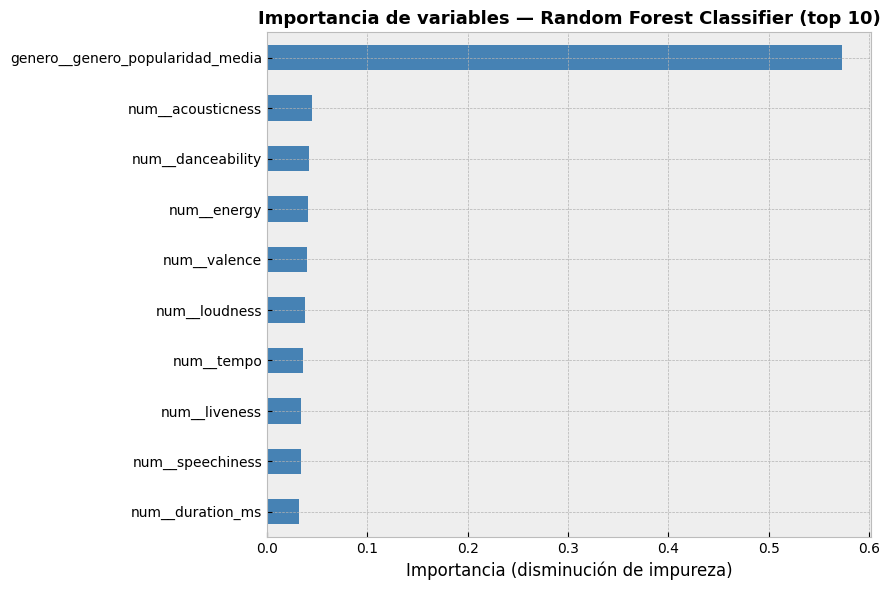

In [20]:
param_dist_cls = {
    'n_estimators': [100, 150, 200, 250, 300],
    'max_depth': [8, 12, 16, 18, 22, None],
    'min_samples_leaf': [1, 2, 3, 5, 8],
    'max_features': ['sqrt', 0.5, 0.7, 1.0],
}

@memoria.cache
def ejecutar_busqueda_rf_clasificador(X_train_prep, y_train_cls, param_dist_cls):
    busqueda = RandomizedSearchCV(
        RandomForestClassifier(random_state=42, n_jobs=1),
        param_distributions=param_dist_cls,
        n_iter=8, cv=3, scoring='accuracy', random_state=42, n_jobs=-1
    )
    busqueda.fit(X_train_prep, y_train_cls)
    return busqueda

busqueda_rf_cls = ejecutar_busqueda_rf_clasificador(X_train_prep, y_train_cls, param_dist_cls)

print(f'Mejor combinación encontrada: {busqueda_rf_cls.best_params_}')
print(f'Accuracy promedio en validación cruzada (train): {busqueda_rf_cls.best_score_:.4f}')

random_forest_cls = busqueda_rf_cls.best_estimator_
pred_rf_cls = random_forest_cls.predict(X_test_prep)
proba_rf_cls = random_forest_cls.predict_proba(X_test_prep)[:, list(random_forest_cls.classes_).index('alta')]

evaluar_clasificador('Random Forest Classifier', y_test_cls, pred_rf_cls)
print(f'AUC-ROC: {roc_auc_score((y_test_cls == "alta").astype(int), proba_rf_cls):.4f}')
print()
print(classification_report(y_test_cls, pred_rf_cls))

importancias_cls = pd.Series(random_forest_cls.feature_importances_, index=X_train_prep.columns)
importancias_cls = importancias_cls.sort_values(ascending=False).head(10)

importancias_cls.sort_values().plot(kind='barh', figsize=(9, 6), color='steelblue')
plt.title('Importancia de variables — Random Forest Classifier (top 10)', fontsize=13, fontweight='bold')
plt.xlabel('Importancia (disminución de impureza)')
plt.tight_layout()
plt.savefig('../images/importancia_variables_clasificador.png', dpi=150, bbox_inches='tight')
plt.show()

### Comparación de modelos de clasificación

                              Accuracy  F1_macro
modelo                                          
Baseline (clase mayoritaria)    0.5013    0.3339
Regresión Logística             0.7768    0.7768
Random Forest Classifier        0.8134    0.8134


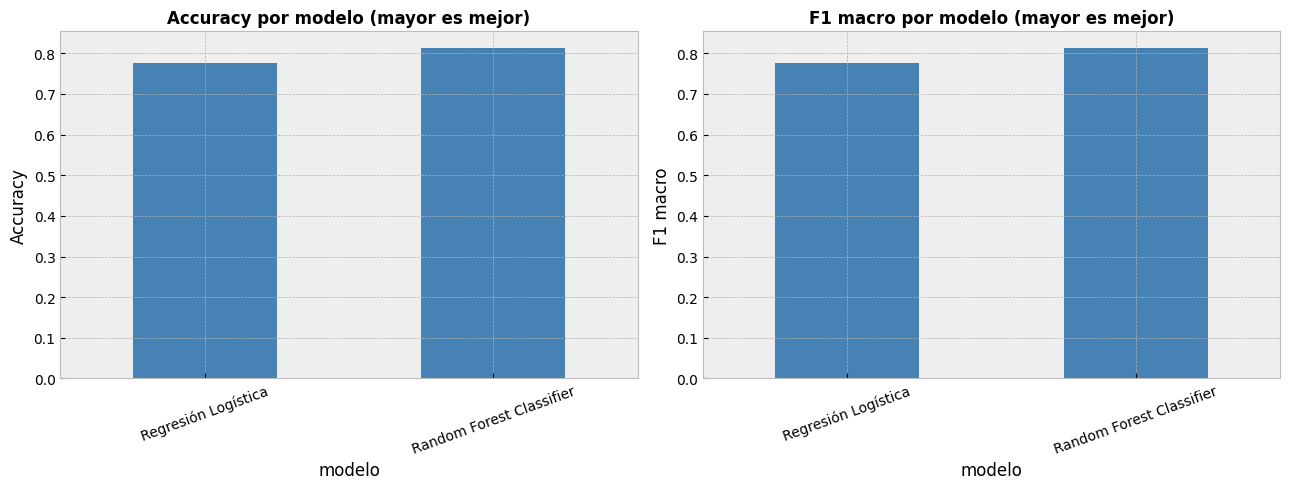


Matriz de confusión — Random Forest Classifier (filas=real, columnas=predicho):
           pred_alta  pred_baja
real_alta       6742       1584
real_baja       1532       6838


In [21]:
tabla_clasificacion = pd.DataFrame(resultados_clasificacion).set_index('modelo')
print(tabla_clasificacion.round(4))

tabla_clasificacion_sin_base = tabla_clasificacion.drop(index='Baseline (clase mayoritaria)')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
tabla_clasificacion_sin_base['Accuracy'].plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Accuracy por modelo (mayor es mejor)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Accuracy')
axes[0].tick_params(axis='x', rotation=20)

tabla_clasificacion_sin_base['F1_macro'].plot(kind='bar', ax=axes[1], color='steelblue')
axes[1].set_title('F1 macro por modelo (mayor es mejor)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('F1 macro')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig('../images/comparacion_clasificacion.png', dpi=150, bbox_inches='tight')
plt.show()

matriz = confusion_matrix(y_test_cls, pred_rf_cls, labels=['alta', 'baja'])
print('\nMatriz de confusión — Random Forest Classifier (filas=real, columnas=predicho):')
print(pd.DataFrame(matriz, index=['real_alta', 'real_baja'], columns=['pred_alta', 'pred_baja']))

**Conexión directa con la regresión: no es un modelo "mejor", es la misma señal con otra
vara de medir.** El Random Forest de regresión (sección 3) ya está entrenado y sus predicciones
continuas (`pred_rf`) están disponibles en este mismo notebook, así que basta con agruparlas en
"alta"/"baja" usando la misma mediana, sin entrenar nada nuevo, para comprobarlo.

In [22]:
pred_cls_desde_regresion = (pd.Series(pred_rf, index=y_test.index) > mediana_train).map({True: 'alta', False: 'baja'})
accuracy_desde_regresion = accuracy_score(y_test_cls, pred_cls_desde_regresion)

print(f'R² del regresor prediciendo el valor exacto:                        {r2_score(y_test, pred_rf):.4f}')
print(f'Accuracy de ESE MISMO regresor, agrupando su predicción en la mediana: {accuracy_desde_regresion:.4f}')
print(f'Accuracy del clasificador entrenado aparte para esta tarea:            {accuracy_score(y_test_cls, pred_rf_cls):.4f}')

R² del regresor prediciendo el valor exacto:                        0.4377
Accuracy de ESE MISMO regresor, agrupando su predicción en la mediana: 0.8000
Accuracy del clasificador entrenado aparte para esta tarea:            0.8134


Los dos números quedan cerca (0,800 vs. 0,813): el clasificador entrenado específicamente no
descubre una relación nueva, solo optimiza un poco mejor la misma frontera que ya estaba
implícita en el regresor (en parte porque su propia búsqueda de hiperparámetros encontró una
configuración distinta a la del regresor). La razón por la que la accuracy binaria (~0,81) es
tan superior al R² de la regresión (~0,44) no es que el modelo "entienda mejor" el problema en
un caso que en el otro: es que clasificar en 2 categorías balanceadas es una pregunta mucho más
tolerante al error que acertar el valor exacto, solo hay **una frontera** que cruzar (la
mediana), y al estar ubicada justo al medio de la distribución, es la configuración más
permisiva posible. Pedirle al modelo más detalle (por ejemplo, más categorías en vez de solo 2)
bajaría la accuracy hacia algo más parecido, aunque nunca idéntico, al R² original, sin que el
modelo haya cambiado en absoluto.

## 6. Aprendizaje no supervisado: segmentación de canciones por sonido (KMeans)

El EDA ya había explorado manualmente un cruce de dos variables (`valence` × `energy`, los 4
"cuadrantes de ánimo") y encontrado que uno de ellos (`es_calmado_positivo`) tiene una
popularidad sistemáticamente distinta a la esperada. Aquí se generaliza esa idea con una
técnica no supervisada: en vez de fijar a mano 2 ejes, se agrupan las canciones usando las
**9 variables de audio ya escaladas** por el pipeline (`danceability`, `energy`, `loudness`,
`speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence`, `tempo`); se excluyen
`duration_ms` y `distancia_duracion_optima` por describir duración y no sonido, y se excluyen
género/variables categóricas y `popularity` para que el agrupamiento refleje únicamente el
**perfil sonoro** de la canción, sin usar la variable objetivo ni información de identidad.

   k      inercia  silhouette
0  2  465661.9751      0.2387
1  3  413325.6923      0.1628
2  4  376903.5187      0.1663
3  5  345582.6055      0.1662
4  6  316835.0960      0.1758
5  7  295695.7103      0.1774
6  8  281431.0956      0.1630


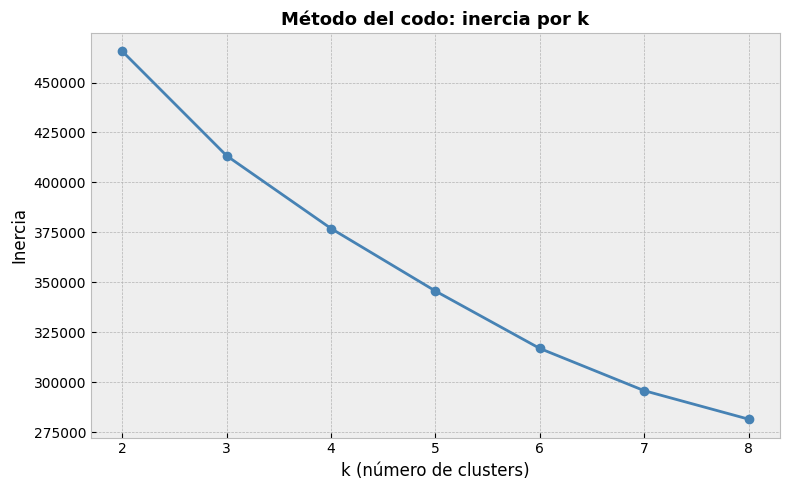

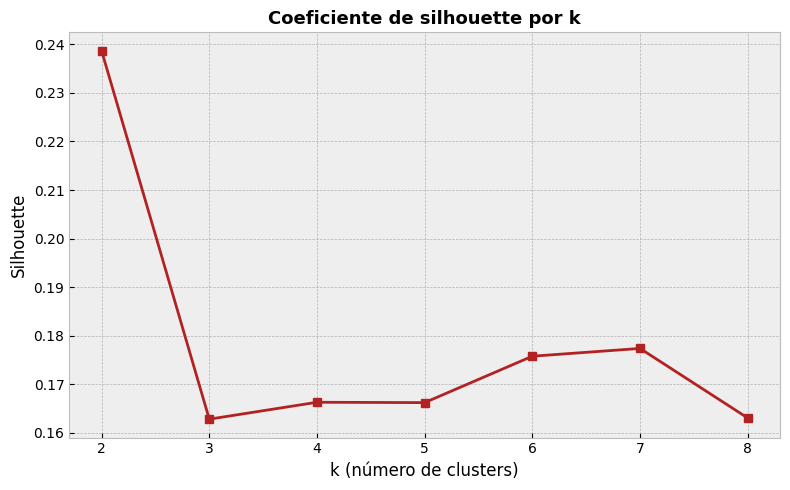

In [23]:
audio_cluster_cols = [
    'num__danceability', 'num__energy', 'num__loudness', 'num__speechiness',
    'num__acousticness', 'num__instrumentalness', 'num__liveness', 'num__valence', 'num__tempo'
]
X_cluster = X_train_prep[audio_cluster_cols]

# Silhouette sobre una muestra fija (8.000 filas) por costo computacional: calcularlo sobre
# las 66.782 filas completas para cada uno de los 7 valores de k es innecesariamente lento y
# no cambia la conclusión (es una medida de cohesión promedio, estable en una muestra grande).
idx_muestra = np.random.RandomState(42).choice(len(X_cluster), size=8000, replace=False)

inertias, siluetas = [], []
valores_k = range(2, 9)
for k in valores_k:
    kmeans_k = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_k.fit(X_cluster)
    inertias.append(kmeans_k.inertia_)
    siluetas.append(silhouette_score(X_cluster.iloc[idx_muestra], kmeans_k.labels_[idx_muestra]))

tabla_k = pd.DataFrame({'k': list(valores_k), 'inercia': inertias, 'silhouette': siluetas})
print(tabla_k.round(4))

plt.figure(figsize=(8, 5))
plt.plot(tabla_k['k'], tabla_k['inercia'], marker='o', color='steelblue')
plt.title('Método del codo: inercia por k', fontsize=13, fontweight='bold')
plt.xlabel('k (número de clusters)')
plt.ylabel('Inercia')
plt.tight_layout()
plt.savefig('../images/elbow_inercia.png', dpi=150, bbox_inches='tight')
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(tabla_k['k'], tabla_k['silhouette'], marker='s', color='firebrick')
plt.title('Coeficiente de silhouette por k', fontsize=13, fontweight='bold')
plt.xlabel('k (número de clusters)')
plt.ylabel('Silhouette')
plt.tight_layout()
plt.savefig('../images/silhouette_clusters.png', dpi=150, bbox_inches='tight')
plt.show()


**Elección de k:** la inercia decrece de forma monótona sin un codo marcado, y el silhouette
más alto es con k=2 (separación binaria, poco accionable para el negocio). A partir de k=3 el
silhouette se aplana entre 0,16 y 0,18 sin diferencias relevantes entre sí. Se elige **k=4**:
cohesión comparable a valores de k mayores, pero con un número de segmentos manejable para una
decisión de negocio (curaduría de playlists, por ejemplo). Es una decisión metodológica que
prioriza interpretabilidad sobre el óptimo matemático puro.

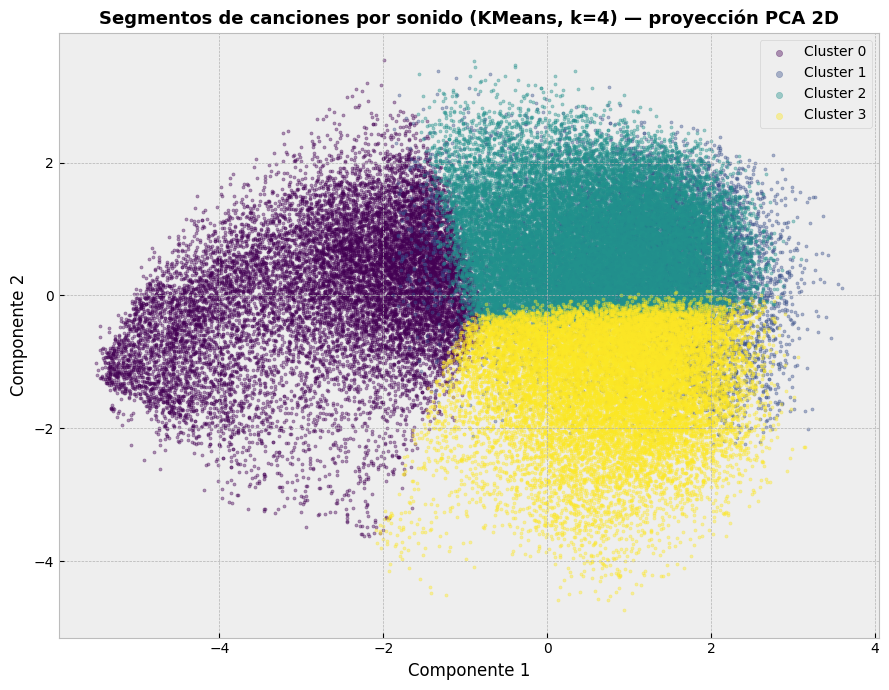

Varianza explicada por las 2 componentes de PCA: 48.9% (se usa solo para visualizar en 2D, el clustering se ajustó sobre las 9 variables)


In [24]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_cluster)

pca = PCA(n_components=2, random_state=42)
coordenadas_2d = pca.fit_transform(X_cluster)
varianza_explicada = pca.explained_variance_ratio_.sum()

# Colores cualitativos (no un degradé continuo como 'viridis'): con un colormap secuencial los
# clusters 1 y 2 (IDs consecutivos) se ven casi del mismo color aunque sean grupos distintos.
colores_cluster = ['#440154', '#3b528b', '#21918c', '#fde725']

plt.figure(figsize=(9, 7))
for c in range(4):
    mascara = clusters == c
    plt.scatter(
        coordenadas_2d[mascara, 0], coordenadas_2d[mascara, 1],
        s=5, alpha=0.4, color=colores_cluster[c], label=f'Cluster {c}'
    )
plt.title('Segmentos de canciones por sonido (KMeans, k=4) — proyección PCA 2D',
          fontsize=13, fontweight='bold')
plt.xlabel('Componente 1')
plt.ylabel('Componente 2')
plt.legend(markerscale=2)
plt.tight_layout()
plt.savefig('../images/clusters_pca.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Varianza explicada por las 2 componentes de PCA: {varianza_explicada:.1%} '
      '(se usa solo para visualizar en 2D, el clustering se ajustó sobre las 9 variables)')

**Proyección en 3D:** con solo 2 componentes, el cluster 1 (hablado/urbano) queda visualmente
mezclado con el 2 (pop/dance alegre): son los dos con `energy`/`danceability` altos, y la
diferencia entre ellos (`speechiness`) pesa poco en las dos primeras componentes. Una tercera
componente ayuda a separarlos mejor.

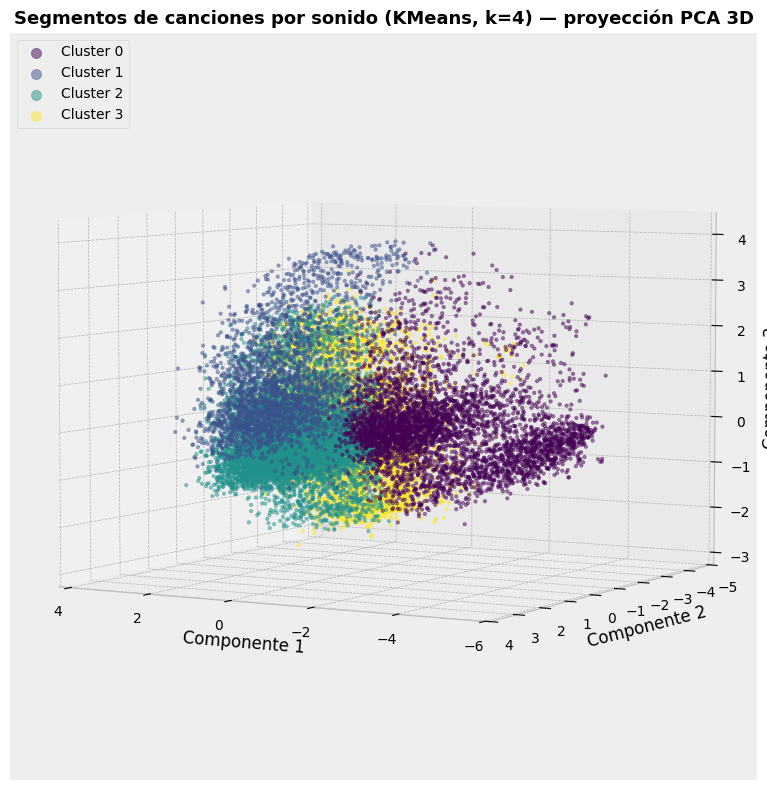

Varianza explicada por las 3 componentes de PCA: 61.0% (vs. 48.9% con solo 2)


In [25]:
pca3 = PCA(n_components=3, random_state=42)
coordenadas_3d = pca3.fit_transform(X_cluster)
varianza_explicada_3d = pca3.explained_variance_ratio_.sum()

# Colores cualitativos (no un degradé continuo como 'viridis'): con un colormap secuencial los
# clusters 1 y 2 (IDs consecutivos) se ven casi del mismo color aunque sean grupos distintos.
# Los extremos de viridis dan 4 colores bien diferenciables entre sí a simple vista.
colores_cluster = ['#440154', '#3b528b', '#21918c', '#fde725']

# Muestra de 20.000 puntos solo para que el gráfico 3D sea legible (66.782 puntos satura
# visualmente cualquier ángulo); el clustering en sí se ajustó sobre los datos completos.
idx_muestra_3d = np.random.RandomState(42).choice(len(coordenadas_3d), size=20000, replace=False)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
for c in range(4):
    mascara = (clusters == c)[idx_muestra_3d]
    ax.scatter(
        coordenadas_3d[idx_muestra_3d][mascara, 0],
        coordenadas_3d[idx_muestra_3d][mascara, 1],
        coordenadas_3d[idx_muestra_3d][mascara, 2],
        s=6, alpha=0.5, color=colores_cluster[c], label=f'Cluster {c}'
    )
ax.set_title('Segmentos de canciones por sonido (KMeans, k=4) — proyección PCA 3D',
              fontsize=13, fontweight='bold')
ax.set_xlabel('Componente 1')
ax.set_ylabel('Componente 2')
ax.set_zlabel('Componente 3')
ax.view_init(elev=5, azim=120)
ax.legend(markerscale=3, loc='upper left')
plt.tight_layout()
plt.savefig('../images/clusters_pca_3d.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Varianza explicada por las 3 componentes de PCA: {varianza_explicada_3d:.1%} '
      f'(vs. {varianza_explicada:.1%} con solo 2)')

In [26]:
columnas_audio_crudo = [
    'danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
    'instrumentalness', 'liveness', 'valence', 'tempo'
]

perfil = X_train.reset_index(drop=True)[columnas_audio_crudo].copy()
perfil['cluster'] = clusters
perfil['popularity'] = y_train.values

resumen_clusters = perfil.groupby('cluster')[columnas_audio_crudo + ['popularity']].mean().round(3)
resumen_clusters['n_canciones'] = perfil['cluster'].value_counts().sort_index()
print(resumen_clusters)

print(f'\nPopularidad promedio global: {y_train.mean():.2f}')


         danceability  energy  loudness  speechiness  acousticness  \
cluster                                                              
0               0.444   0.275   -15.197        0.049         0.766   
1               0.676   0.698    -7.203        0.286         0.302   
2               0.660   0.682    -7.113        0.049         0.277   
3               0.461   0.826    -5.930        0.074         0.068   

         instrumentalness  liveness  valence    tempo  popularity  n_canciones  
cluster                                                                         
0                   0.366     0.175    0.274  110.156      31.964        14607  
1                   0.043     0.275    0.564  121.550      34.841         9169  
2                   0.075     0.189    0.656  119.405      36.760        24401  
3                   0.248     0.268    0.315  136.411      33.899        18605  

Popularidad promedio global: 34.65


**Interpretación de los segmentos** (sobre el perfil de audio sin escalar, valores promedio
por cluster):

- **Cluster 0, Acústico/calmado** (`danceability` y `energy` bajos, `acousticness` alto ~0,77,
  volumen bajo ~-15 dB, `valence` bajo): sonido introspectivo, poco bailable. Es el segmento con
  **menor popularidad promedio**.
- **Cluster 1, Hablado/urbano** (`speechiness` notoriamente más alto que el resto, ~0,29,
  `danceability`/`energy` medio-altos): perfil consistente con rap/hip-hop.
- **Cluster 2, Pop/dance alegre** (el más numeroso; `danceability`, `energy` y `valence`
  altos, `acousticness` y `speechiness` bajos): sonido bailable y positivo. Es el segmento con
  **mayor popularidad promedio**.
- **Cluster 3, Intenso/instrumental** (`energy` el más alto de los 4, tempo el más rápido,
  `instrumentalness` elevado, `valence` bajo): sonido enérgico pero no necesariamente alegre
  (p. ej. electrónica instrumental o rock/metal).

La diferencia de popularidad promedio entre clusters es acotada (~5 puntos de `popularity`
entre el cluster más bajo y el más alto, sobre una media global de 34,65), **coherente con el
hallazgo central del EDA**: el sonido por sí solo tiene una relación real pero débil con la
popularidad. El segmento de menor popularidad (acústico/calmado, `valence` bajo) es además
consistente con la variable `es_calmado_positivo`: ahí el hallazgo fue sobre un cuadrante de
*valence* alto/*energy* bajo; aquí, usando las 9 variables de audio en conjunto, el segmento más
penalizado es uno con *valence* igualmente bajo, reforzando que el ánimo "poco enérgico y poco
positivo" del sonido se asocia con menor tracción, más allá de qué par de variables se use para
definirlo.

## 7. Evaluación de resultados y recomendaciones de negocio

Retomando la pregunta de negocio (¿qué tan bien explican el sonido y el género la popularidad,
independientemente de la fama del artista?), ambos modelos confirman de forma cuantitativa,
extremo a extremo, lo que el EDA ya anticipaba con correlaciones simples:

- El mejor modelo (Random Forest ajustado) explica **~44% de la varianza** de `popularity`
  (R²≈0,44) usando solo sonido y género, muy por encima de la línea base (R²≈0) y de la
  regresión lineal (R²≈0,39), pero lejos de una predicción perfecta.
- El género sigue siendo, por lejos, la variable más importante del modelo
  (`feature_importances_` del Random Forest), coherente con el techo de señal medido en el EDA
  (correlación de género ≈0,62 contra ≤0,13 de cualquier variable de audio).
- La segmentación por sonido confirma, con una técnica independiente (no supervisada, sin ver
  `popularity` durante el ajuste), que existen diferencias reales pero acotadas de popularidad
  entre distintos "perfiles sonoros".

**Recomendación de negocio:** el modelo (y los segmentos de sonido) pueden usarse como una señal
de apoyo para priorizar qué escuchar primero entre material nuevo de artistas sin trayectoria,
el caso de uso real del problema de negocio, nunca como filtro automático ni como sustituto del
criterio humano: con R²≈0,44, más de la mitad de la varianza de `popularity` queda sin explicar
por el contenido de la canción, y una parte de esa varianza no observada corresponde a contexto
de publicación y a la fama del artista, que se excluyó deliberadamente del modelo por razones
éticas. El modelo responde "qué tan prometedora suena esta canción en sí misma", no "qué tan
exitosa será": son preguntas distintas y el negocio debe tratarlas como tales.

# Resumen

- Se reconstruyó el dataset preparado (83.478 canciones, 66.782 entrenamiento / 16.696 prueba,
  29 columnas) con el mismo pipeline de `preprocesamiento.ipynb`, verificado sin valores nulos.
- **Modelos supervisados de regresión:** línea base ingenua (R²≈0) < Regresión Lineal
  (R²≈0,39) < Random Forest (R²≈0,44). El Random Forest se ajustó con `RandomizedSearchCV`
  (8 combinaciones × 3 folds sobre un espacio de 600 posibles) en vez de una configuración
  elegida a mano, confirmando una mejora real sobre los valores por defecto de scikit-learn
  (R²≈0,43). El género (`genero_popularidad_media`) domina la importancia de variables del
  Random Forest, consistente con el hallazgo del EDA.
- **Modelos supervisados de clasificación (complemento):** clasificar `popularity` como
  alta/baja respecto a la mediana alcanza **0,8134 de accuracy** con Random Forest (ajustado
  con `RandomizedSearchCV`, AUC-ROC=0,8935), mucho más alto que el R²≈0,44 de la regresión,
  pero **no por una señal nueva**: se verificó agrupando la predicción continua del propio
  regresor de regresión en la mediana (sin entrenar nada nuevo), que da una accuracy de 0,800,
  cercana a la del clasificador dedicado. Clasificar en 2 categorías balanceadas es una
  pregunta más tolerante al error que acertar el valor exacto, no un problema distinto resuelto
  mejor.
- **Modelo no supervisado:** KMeans (k=4, elegido por elbow + silhouette, priorizando
  interpretabilidad de negocio) segmenta las canciones por perfil de sonido en 4 grupos con
  diferencias de popularidad acotadas (~5 puntos de rango), reforzando con una técnica
  independiente el hallazgo central del EDA.
- Todos los resultados se interpretan en términos del problema de negocio del proyecto: el
  sonido y el género aportan una señal real pero limitada (techo ≈0,44 de R²), deliberadamente
  sin usar identidad de artista/álbum, por lo que el modelo debe usarse como apoyo a la decisión
  humana, no como reemplazo.
- **Próximos pasos** (fuera de alcance de esta entrega): una búsqueda de hiperparámetros más
  amplia que la acotada aquí (más combinaciones, `GridSearchCV` sobre el entorno de la mejor
  combinación encontrada), modelos de gradient boosting, y consideraciones de despliegue
  (fase 6 de CRISP-DM).